# DỰ BÁO GIÁ NHÀ AMES BẰNG MACHINE LEARNING — DETAILED NOTEBOOK

**Bài toán:** hồi quy dự báo `SalePrice` trên Ames Housing  
**Protocol:** Development → MODEL LOCK → Final Holdout Test  
**Canonical technical source:** `src/house_price/` + `outputs/summary.json`

Notebook này là bản trình bày học thuật chi tiết của pipeline final. Mục tiêu không phải tạo một training pipeline thứ hai, mà là **giải thích, kiểm chứng và tái hiện có kiểm soát** những bằng chứng canonical đã được project sinh ra.

Điểm quan trọng của bản notebook này:

- giữ nguyên split 80/10/10 đã cung cấp, không chia lại dữ liệu;
- giữ nguyên model final và hyperparameters của project;
- chỉ dùng **train + validation** trong giai đoạn phát triển và lựa chọn mô hình;
- final holdout test chỉ được mở sau bước khóa mô hình;
- feature engineering, preprocessing, selection và inference được import từ source production thay vì copy logic vào notebook;
- mọi bảng/figure canonical đều phải vượt qua freshness gate trước khi được tin cậy.


## 1. Mục tiêu nghiên cứu và protocol chống data leakage

### Câu hỏi nghiên cứu

1. Những đặc trưng nào có quan hệ mạnh với giá bán nhà trong tập Ames hiện có?
2. Các token như `NA`/`None` nên được hiểu thế nào để không phá vỡ ngữ nghĩa dữ liệu?
3. Feature engineering và preprocessing được tổ chức ra sao để tránh leakage và vẫn phục vụ deployment?
4. Trong cùng một protocol, các mô hình hồi quy khác nhau tổng quát hóa thế nào trên validation?
5. Vì sao ElasticNet được chọn thay vì Ridge hoặc các mô hình cây?
6. Sau khi quyết định được khóa, model hoạt động ra sao trên holdout test và thường sai ở nhóm nhà nào?

### Ba pha bắt buộc

**Phase A — Development:** chỉ sử dụng train + validation cho audit, EDA, benchmark, tuning và selection.  
**Phase B — MODEL LOCK:** đối chiếu executable policy, model name và hyperparameters đã khóa.  
**Phase C — Final Test:** chỉ sau bước lock mới load holdout test, tách target và thực hiện đánh giá cuối.

Trong notebook này, checksum của file test có thể được kiểm tra trước lock để xác nhận đúng file, nhưng **không đọc target hoặc thống kê target test** trước khi quyết định mô hình được khóa.


In [1]:
from pathlib import Path
import hashlib, json, platform, sys

import joblib
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from house_price.config import ENGINEERED_FEATURES, RANDOM_STATE, TARGET, ID_COLUMN
from house_price.data import load_house_data, split_xy, sha256_file

np.random.seed(RANDOM_STATE)
print("PROJECT_ROOT: <project root detected>")
print({
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "random_state": RANDOM_STATE,
})


PROJECT_ROOT: <project root detected>
{'Python': '3.13.5', 'pandas': '2.2.3', 'numpy': '2.3.5', 'scikit-learn': '1.8.0', 'random_state': 42}


## Phase A — DEVELOPMENT: dữ liệu, EDA, benchmark và tuning

### 2. Đọc dữ liệu có kiểm soát ngữ nghĩa thiếu

Ames Housing có nhiều biến mà `NA`/`None` mang nghĩa **không có tiện ích** (ví dụ không có hồ bơi, hẻm, hàng rào, một số loại veneer...) chứ không nhất thiết là lỗi thu thập. Vì vậy việc đọc dữ liệu phải bảo toàn các token có nghĩa và chỉ ép kiểu những cột thực sự là số.

Trong Phase A, notebook **chỉ load train và validation**. `Id` và `SalePrice` được tách khỏi ma trận đặc trưng trước khi mô hình học. Việc giữ hai split riêng giúp validation phản ánh khả năng tổng quát hóa trong quá trình phát triển, còn holdout test vẫn độc lập cho đánh giá cuối.


In [2]:
train = load_house_data("house_train_80.csv")
validation = load_house_data("house_validation_10.csv")

assert train.shape == (1168, 81)
assert validation.shape == (146, 81)
assert list(train.columns) == list(validation.columns)
assert TARGET in train.columns and TARGET in validation.columns
assert not train[ID_COLUMN].duplicated().any()
assert not validation[ID_COLUMN].duplicated().any()
assert set(train[ID_COLUMN]).isdisjoint(set(validation[ID_COLUMN]))

X_train, y_train = split_xy(train)
X_val, y_val = split_xy(validation)
assert TARGET not in X_train.columns and ID_COLUMN not in X_train.columns
assert list(X_train.columns) == list(X_val.columns)

split_overview = pd.DataFrame([
    {"Split": "Train", "Rows": len(train), "Raw_features": X_train.shape[1], "Target_mean": y_train.mean(), "Target_median": y_train.median()},
    {"Split": "Validation", "Rows": len(validation), "Raw_features": X_val.shape[1], "Target_mean": y_val.mean(), "Target_median": y_val.median()},
])
print("Development shapes:", X_train.shape, X_val.shape)
display(split_overview.round(2))
display(train[[ID_COLUMN, "MSSubClass", "Neighborhood", "OverallQual", "GrLivArea", TARGET]].head(5))


Development shapes: (1168, 79) (146, 79)


,Split,Rows,Raw_features,Target_mean,Target_median
0,Train,1168,79,180976.89,163000.0
1,Validation,146,79,182683.40,162500.0


,Id,MSSubClass,Neighborhood,OverallQual,GrLivArea,SalePrice
0,1,60,CollgCr,7,1710,208500
1,2,20,Veenker,6,1262,181500
2,3,60,CollgCr,7,1786,223500
3,6,50,Mitchel,5,1362,143000
4,7,20,Somerst,8,1694,307000


### 3. Freshness gate — chỉ tin evidence khi còn khớp source/data/artifact

Một notebook có thể chạy không lỗi nhưng vẫn sai nếu nó đọc `summary.json`, model hoặc figure được sinh từ một phiên bản source cũ. Vì vậy trước khi dùng canonical outputs, notebook kiểm tra:

- SHA-256 của ba file dữ liệu cố định;
- SHA-256 của canonical model artifact;
- selected model và selected params giữa summary và selection policy;
- source fingerprint của các module trọng yếu;
- timestamp sinh evidence.

Đối với holdout test, giai đoạn này **chỉ băm bytes của file**; không gọi loader và không đọc `SalePrice` test. Nếu có mismatch, notebook dừng với `STALE EVIDENCE` thay vì tự động retrain và làm thay đổi project.


In [3]:
summary_path = ROOT / "outputs" / "summary.json"
policy_path = ROOT / "outputs" / "model_selection_policy.json"
fingerprint_path = ROOT / "outputs" / "source_fingerprint.json"

summary = json.loads(summary_path.read_text(encoding="utf-8"))
policy = json.loads(policy_path.read_text(encoding="utf-8"))
fingerprint = json.loads(fingerprint_path.read_text(encoding="utf-8"))

issues = []
verified_hashes = []
for item in summary.get("data_hashes", []):
    path = ROOT / item["file"]
    actual = sha256_file(path)
    if actual != item["sha256"]:
        issues.append(f"data hash mismatch: {item['file']}")
    verified_hashes.append({"file": item["file"], "bytes": item["bytes"], "sha256_prefix": actual[:16]})

model_path = ROOT / summary["artifact"]["path"]
actual_model_hash = sha256_file(model_path)
if actual_model_hash != summary["artifact"]["model_sha256"]:
    issues.append("artifact hash mismatch")
if summary["selected_model"] != policy["locked_model"]:
    issues.append("selected model mismatch")
if summary["selected_params"] != policy["locked_params"]:
    issues.append("selected params mismatch")
for rel, expected in fingerprint.get("files", {}).items():
    if sha256_file(ROOT / rel) != expected:
        issues.append(f"source fingerprint mismatch: {rel}")
if not summary.get("generated_at_utc") or not fingerprint.get("generated_at_utc"):
    issues.append("missing generated_at timestamp")

if issues:
    raise RuntimeError("STALE EVIDENCE: " + "; ".join(issues) + ". Regenerate canonical evidence before using this notebook.")

print("FRESHNESS: PASS")
print("canonical summary:", summary["generated_at_utc"])
print("source fingerprint:", fingerprint["generated_at_utc"])
print("artifact SHA-256:", actual_model_hash)
display(pd.DataFrame(verified_hashes))


FRESHNESS: PASS
canonical summary: 2026-08-26T11:51:25.286277+00:00
source fingerprint: 2026-08-26T17:29:25.344975+00:00
artifact SHA-256: 5101114637e8001c91f06a42737cd3cc8ee143cb1d6a3a27631a41b48f3efcf1


,file,bytes,sha256_prefix
0,data/house_train_80.csv,369865,6af30124e1522a6b
1,data/house_validation_10.csv,46936,58828c452645ee31
2,data/house_test_10.csv,47057,a0f077b3f0900742


### 4. EDA: hiểu dữ liệu trước khi mô hình hóa

EDA ở đây tập trung vào **train**, còn validation chỉ được dùng để kiểm tra mức độ dịch chuyển phân phối ở một số biến chính. Không có target test trong bất kỳ biểu đồ nào của Phase A.

Các kết luận quan trọng từ canonical EDA:

- `SalePrice` train lệch phải mạnh: skewness khoảng **1.888**; sau `log1p`, skewness giảm còn khoảng **0.168**. Điều này hỗ trợ việc dùng log-target để giảm ảnh hưởng của đuôi giá rất cao.
- `OverallQual` và `GrLivArea` là hai tín hiệu số mạnh nhất; tiếp theo là `GarageCars`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`.
- `Neighborhood` và các biến chất lượng phân loại tạo chênh lệch giá rõ, nên không thể chỉ giữ biến số.
- Tương quan Pearson giúp sàng lọc quan hệ tuyến tính nhưng **không chứng minh quan hệ nhân quả**.
- Tỷ lệ absence cao ở một số cột phản ánh cấu trúc của căn nhà, không nên xóa cột chỉ vì tỷ lệ `NA` lớn.
- Standardized mean difference giữa train và validation ở các biến kiểm tra đều dưới ngưỡng cảnh báo 0.2 trong evidence hiện tại.


Target statistics (train only):


,count,mean,median,std,min,q1,q3,q95,max,skewness,log1p_skewness
0,1168,180976.886,163000.0,79285.166,34900.0,129975.0,213625.0,328585.0,755000.0,1.888,0.168


Top semantic missing/absence:


,Column,Missing_or_absence_count,Missing_or_absence_pct
0,PoolQC,1161,99.40
1,MiscFeature,1125,96.32
2,Alley,1095,93.75
3,Fence,943,80.74
4,MasVnrType,693,59.33
5,FireplaceQu,555,47.52
6,LotFrontage,212,18.15
7,GarageQual,63,5.39
8,GarageFinish,63,5.39
9,GarageType,63,5.39


Top numeric correlations with SalePrice:


,Feature,Correlation_with_SalePrice
0,OverallQual,0.7903
1,GrLivArea,0.7052
2,GarageCars,0.6377
3,GarageArea,0.6084
4,TotalBsmtSF,0.5994
5,1stFlrSF,0.5980
6,FullBath,0.5531
7,TotRmsAbvGrd,0.5179
8,YearRemodAdd,0.5138
9,YearBuilt,0.5123


Train → validation drift check:


,Feature,Split,Train_mean,Split_mean,Standardized_mean_difference,Flag_abs_gt_0_2
0,OverallQual,Validation,6.1045,6.1233,0.0137,False
1,GrLivArea,Validation,1519.6884,1469.8219,-0.0939,False
2,GarageCars,Validation,1.7637,1.8151,0.0703,False
3,TotalBsmtSF,Validation,1058.5163,1072.7329,0.0323,False
4,YearBuilt,Validation,1971.1550,1972.2397,0.0359,False
5,SalePrice,Validation,180976.8861,182683.3973,0.0215,False


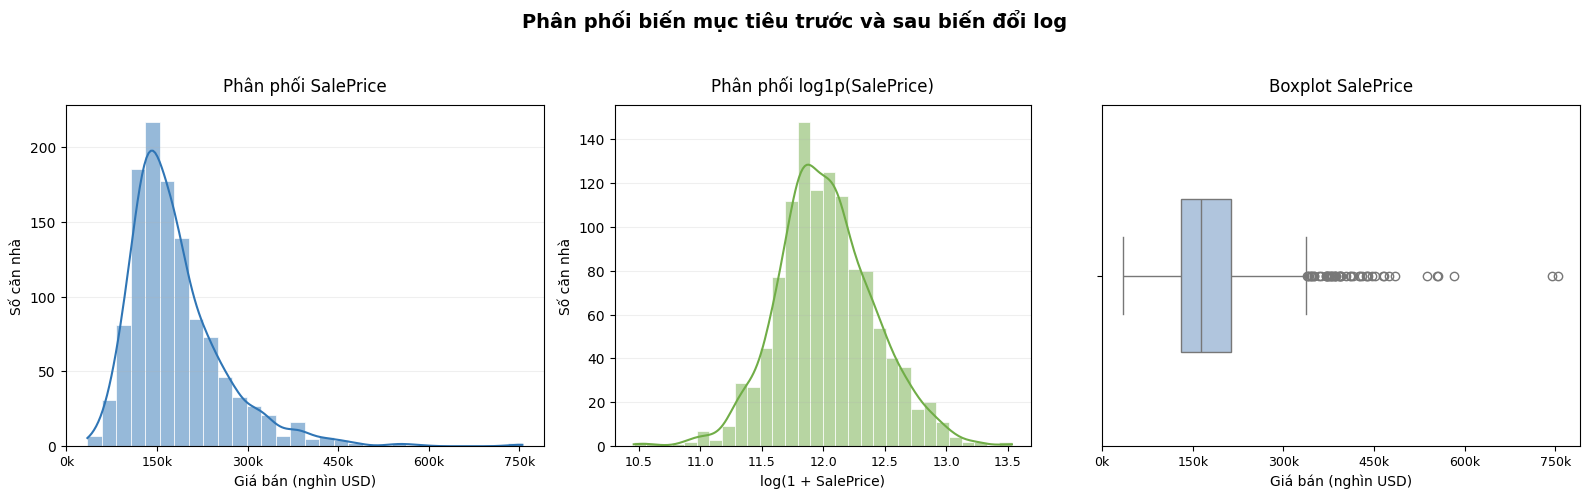

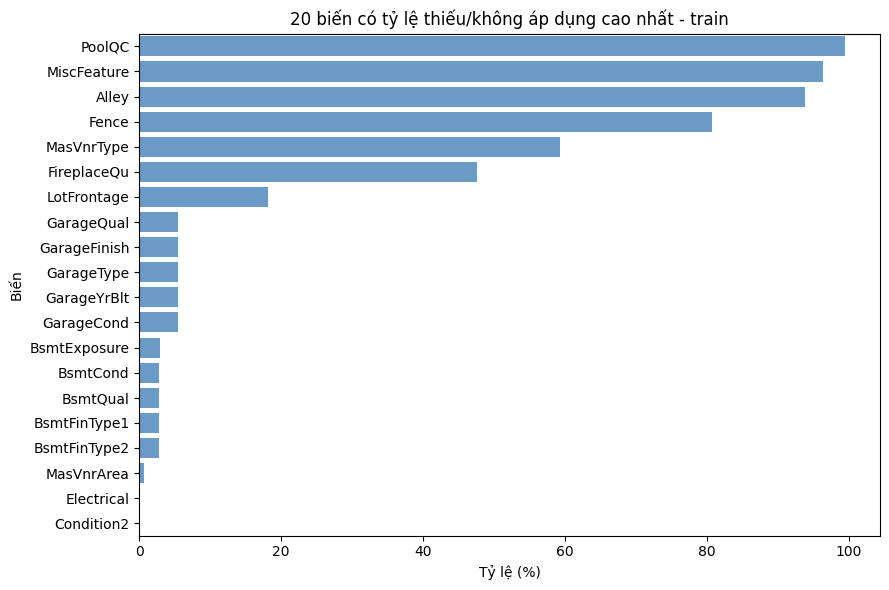

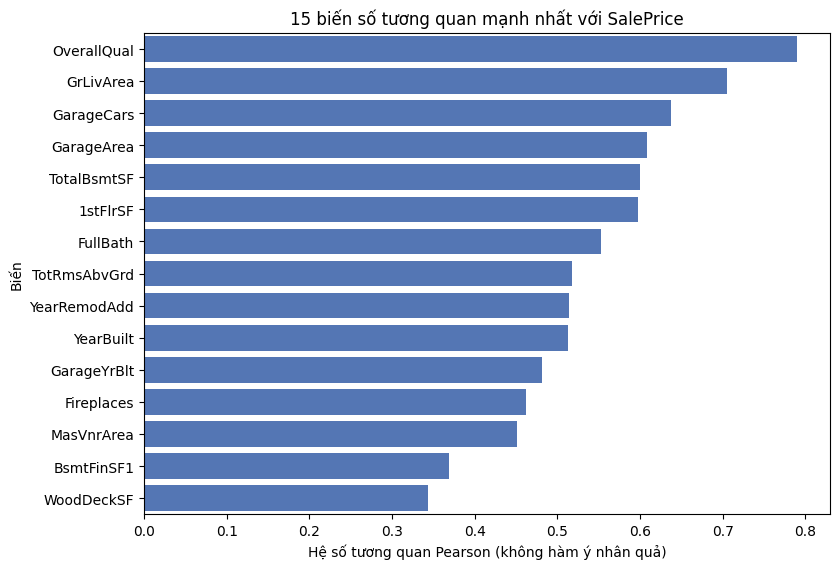

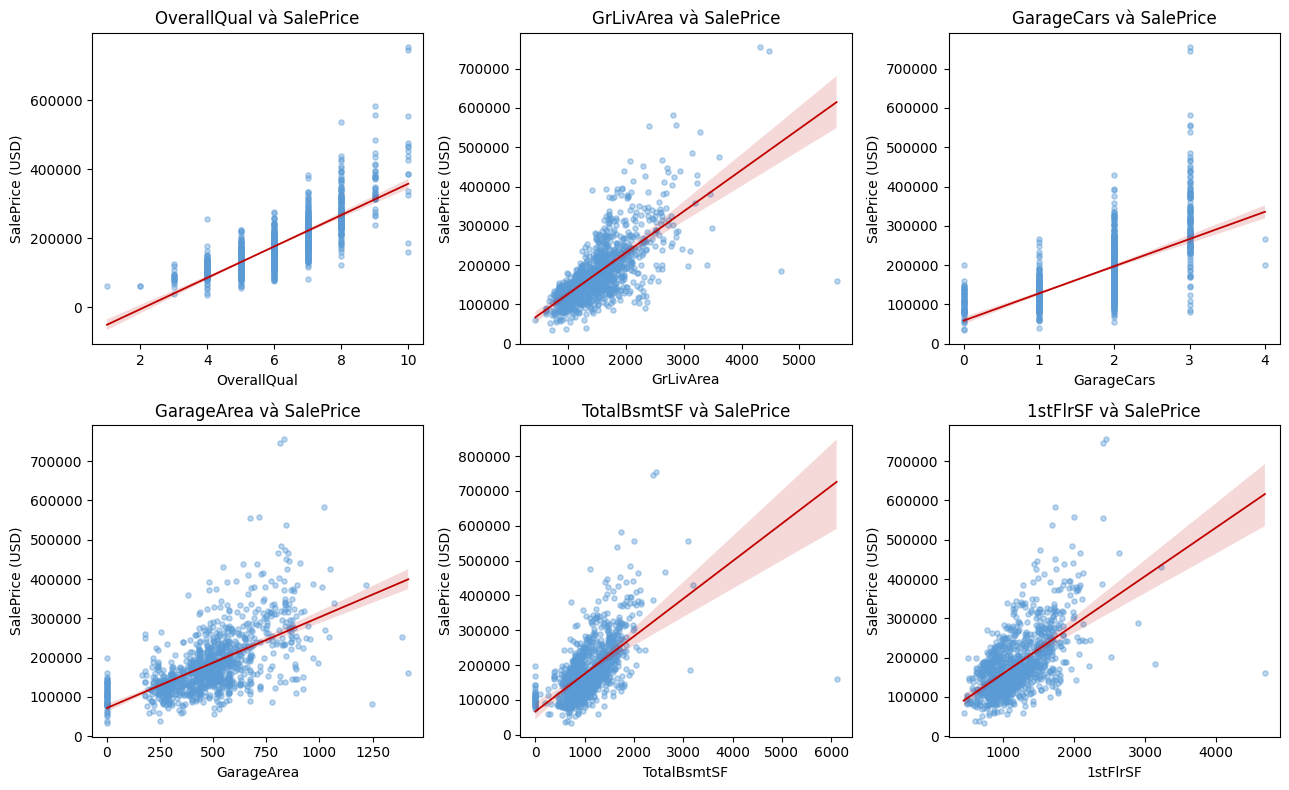

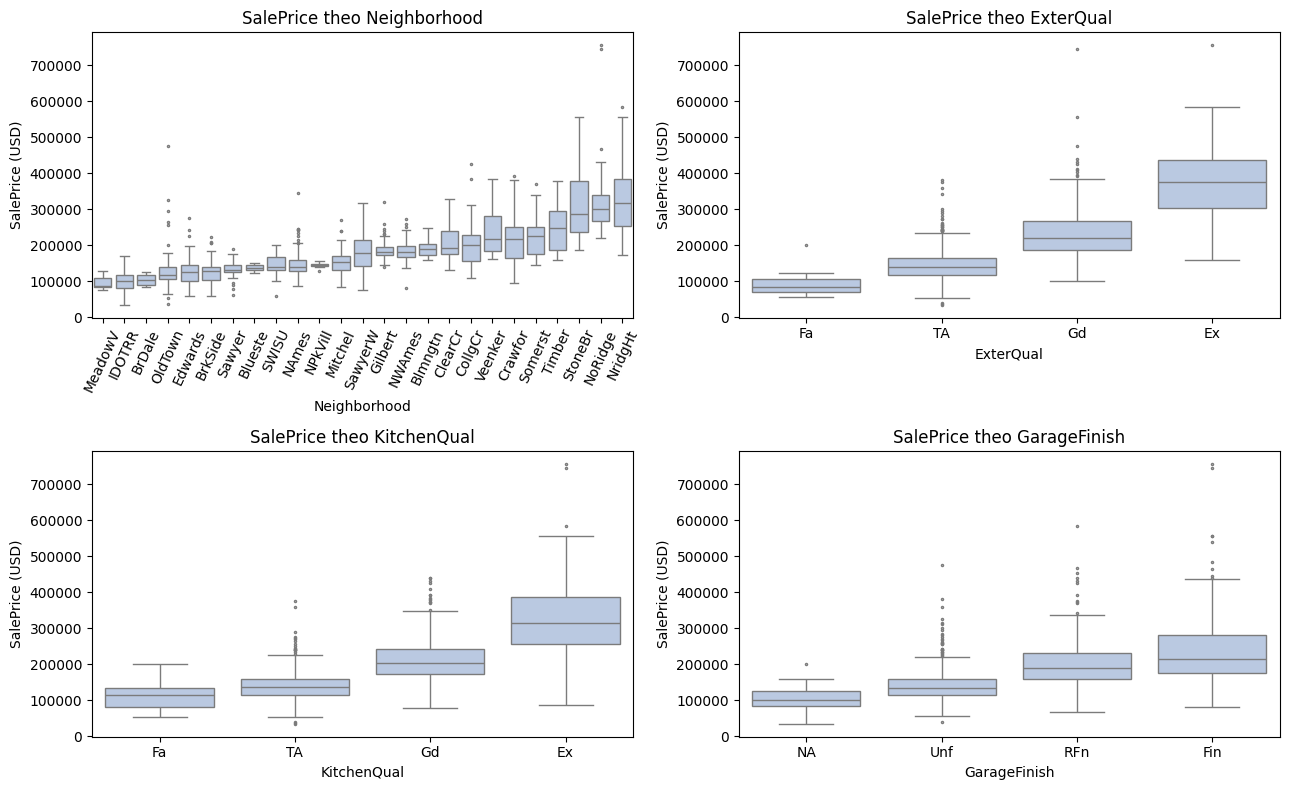

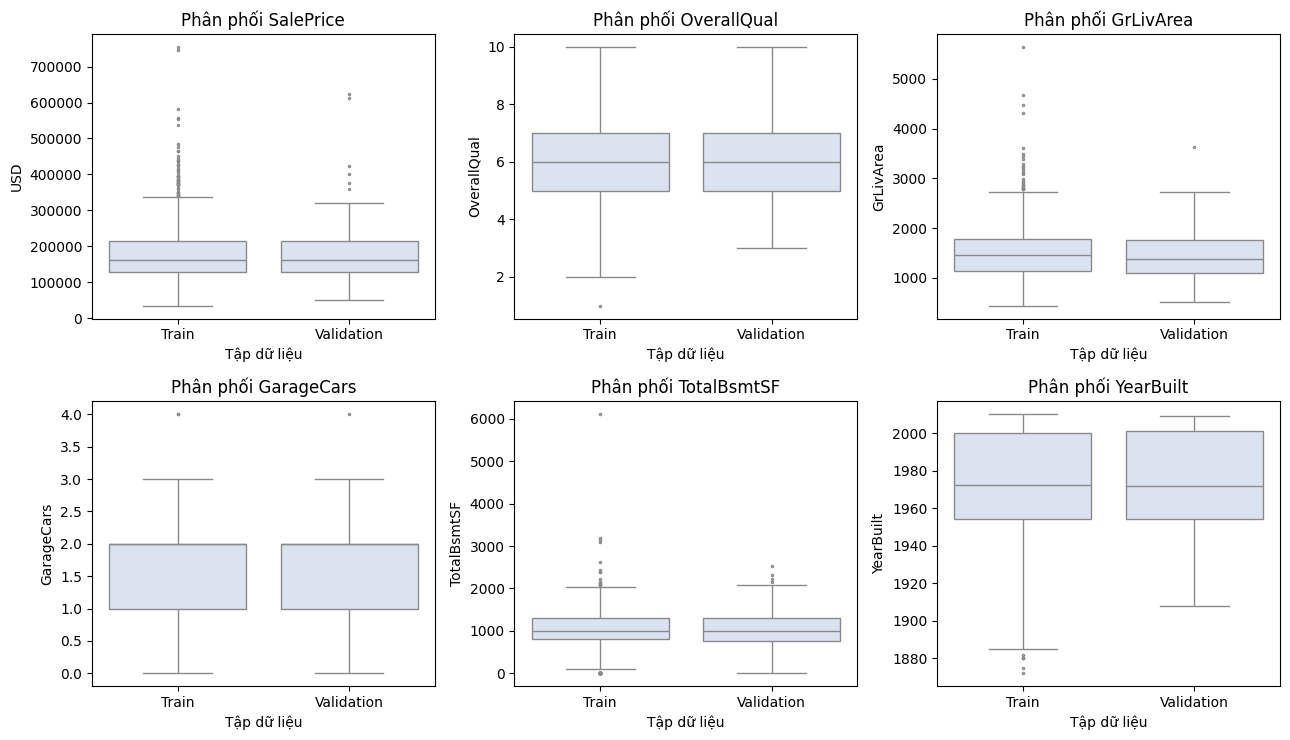

In [4]:
# Kiểm tra lại thống kê train trực tiếp và đối chiếu canonical EDA tables.
target_stats_now = {
    "count": int(y_train.count()),
    "mean": float(y_train.mean()),
    "median": float(y_train.median()),
    "std": float(y_train.std()),
    "min": float(y_train.min()),
    "q1": float(y_train.quantile(0.25)),
    "q3": float(y_train.quantile(0.75)),
    "q95": float(y_train.quantile(0.95)),
    "max": float(y_train.max()),
    "skewness": float(y_train.skew()),
    "log1p_skewness": float(np.log1p(y_train).skew()),
}
for key, value in target_stats_now.items():
    assert np.isclose(value, summary["target_stats"][key])

data_dictionary = pd.read_csv(ROOT / "outputs" / "tables" / "data_dictionary.csv")
missing_top = pd.read_csv(ROOT / "outputs" / "tables" / "missingness_top20.csv")
correlations = pd.read_csv(ROOT / "outputs" / "tables" / "numeric_correlations.csv")
drift = pd.read_csv(ROOT / "outputs" / "tables" / "split_drift_numeric.csv")
assert set(drift["Split"]) == {"Validation"}

print("Target statistics (train only):")
display(pd.DataFrame([target_stats_now]).round(3))
print("Top semantic missing/absence:")
display(missing_top.head(12).round(2))
print("Top numeric correlations with SalePrice:")
display(correlations.head(15).round(4))
print("Train → validation drift check:")
display(drift.round(4))

for filename in [
    "01_target_distribution.png",
    "02_missingness_top20.png",
    "03_top_numeric_correlations.png",
    "04_numeric_relationships.png",
    "05_categorical_relationships.png",
    "06_split_distribution_check.png",
]:
    display(Image(filename=str(ROOT / "outputs" / "figures" / filename)))


### 5. Feature engineering, preprocessing và log-target

Project không tạo feature bằng thống kê của test hoặc bằng `SalePrice`; các feature mới là phép biến đổi theo từng dòng:

- tuổi nhà/cải tạo/gara tại thời điểm bán;
- tổng diện tích sàn, tổng phòng tắm quy đổi, tổng diện tích hiên/ngoài trời;
- các cờ có/không có gara, tầng hầm, lò sưởi, hồ bơi, tầng 2, veneer;
- `MoSold_sin`/`MoSold_cos` để mã hóa tính chu kỳ của tháng bán.

Pipeline cuối nhận **79 raw features** và tự tạo thêm **15 features**. Sau đó:

- numeric: median imputation → standardization;
- categorical: constant `Missing` → one-hot với `handle_unknown='ignore'`;
- target: $z=\log(1+y)$ trong lúc fit và $\hat y=\exp(\hat z)-1$ khi dự báo.

Feature engineering nằm **bên trong saved artifact**, nên backend/Streamlit không phải copy lại công thức. Đây là khác biệt quan trọng giữa một notebook demo và một artifact có thể phục vụ inference ổn định.


In [5]:
from house_price.features import engineer_features
from house_price.modeling import build_end_to_end_estimator, model_definitions
from house_price.preprocessing import build_preprocessor

engineered_sample = engineer_features(X_train.head(5))
preprocessor, numeric_features, categorical_features = build_preprocessor(X_train)
probe_estimator = build_end_to_end_estimator(X_train, model_definitions()[summary["selected_model"]])
feature_table = pd.read_csv(ROOT / "outputs" / "tables" / "feature_engineering.csv")

assert X_train.shape[1] == summary["dataset"]["input_features_raw"] == 79
assert engineered_sample.shape[1] == summary["dataset"]["engineered_feature_count"] == 94
assert len(ENGINEERED_FEATURES) == summary["dataset"]["engineered_features_added"] == 15

print("Raw → engineered:", X_train.shape[1], "→", engineered_sample.shape[1])
print("Numeric / categorical after FE:", len(numeric_features), "/", len(categorical_features))
print("End-to-end steps:", list(probe_estimator.regressor.named_steps.keys()))
display(feature_table)


Raw → engineered: 79 → 94
Numeric / categorical after FE: 50 / 44
End-to-end steps: ['feature_engineering', 'preprocessor', 'model']


,Feature,Formula,Meaning
0,HouseAge,YrSold - YearBuilt,Tuổi nhà tại thời điểm bán
1,RemodAge,YrSold - YearRemodAdd,Tuổi từ lần cải tạo
2,GarageAge,YrSold - GarageYrBlt,Tuổi gara
3,TotalSF,TotalBsmtSF + 1stFlrSF + 2ndFlrSF,Tổng diện tích sàn
4,TotalBathrooms,Full + 0.5 Half + basement,Tổng phòng tắm quy đổi
5,TotalPorchSF,Tổng 5 loại hiên/sàn,Không gian hiên
6,TotalOutdoorSF,TotalPorchSF + PoolArea,Không gian ngoài trời
7,HasGarage/HasBsmt/HasFireplace/HasPool/Has2ndF...,Cờ 0/1,Có/không tiện ích
8,MoSold_sin/cos,sin/cos(2π MoSold/12),Mã hóa chu kỳ tháng


### 6. Chỉ số đánh giá và thiết kế benchmark

Đây là **bài toán hồi quy**, vì vậy Accuracy, Precision, Recall và F1 không phải thước đo phù hợp.

- **RMSE** — chỉ số chính; cùng đơn vị USD và phạt mạnh các sai số lớn.
- **MAE** — sai số tuyệt đối trung bình, trực quan khi giải thích cho người dùng.
- **R²** — tỷ lệ biến thiên target được mô hình giải thích tương đối so với dự báo trung bình.
- **RMSLE** — nhạy với sai số theo tỷ lệ và giảm mức chi phối tuyệt đối của nhà rất đắt.

Benchmark canonical gồm **Dummy baseline + 9 mô hình thực**. Mọi mô hình đều đi qua cùng raw-input → feature engineering → preprocessing → log-target contract để phép so sánh công bằng hơn. `Train_RMSE`, `Validation_RMSE` và `RMSE_gap` được đọc cùng nhau: RMSE train cực thấp nhưng validation cao có thể là dấu hiệu phương sai lớn/overfitting, không phải bằng chứng model tốt.


Real candidate models: 9 ['LinearRegression', 'Ridge', 'ElasticNet', 'KNeighborsRegressor', 'DecisionTreeRegressor', 'RandomForestRegressor', 'ExtraTreesRegressor', 'GradientBoostingRegressor', 'HistGradientBoostingRegressor']


,Model,Train_RMSE,RMSE,MAE,R2,RMSLE,RMSE_gap,Relative_to_dummy_RMSE_improvement_pct,Gap_ratio
0,ElasticNet,20829.0,24856.0,15376.0,0.9172,0.1202,4026.0,71.95,0.162
1,Ridge,22598.0,25213.0,15385.0,0.9148,0.1212,2616.0,71.55,0.104
2,LinearRegression,16531.0,26277.0,16712.0,0.9075,0.1542,9746.0,70.35,0.371
3,ExtraTreesRegressor,0.0,26552.0,16503.0,0.9056,0.1404,26552.0,70.04,1.000
4,RandomForestRegressor,12995.0,27861.0,14377.0,0.8960,0.1200,14866.0,68.56,0.534
5,DecisionTreeRegressor,21878.0,31458.0,22220.0,0.8674,0.1707,9579.0,64.50,0.305
6,KNeighborsRegressor,0.0,34184.0,19292.0,0.8435,0.1537,34184.0,61.42,1.000
7,HistGradientBoostingRegressor,31298.0,36644.0,18140.0,0.8201,0.1415,5346.0,58.65,0.146
8,GradientBoostingRegressor,46569.0,53014.0,27105.0,0.6235,0.2117,6445.0,40.17,0.122
9,DummyRegressor (median),81265.0,88612.0,58271.0,-0.0519,0.4178,7348.0,0.00,0.083


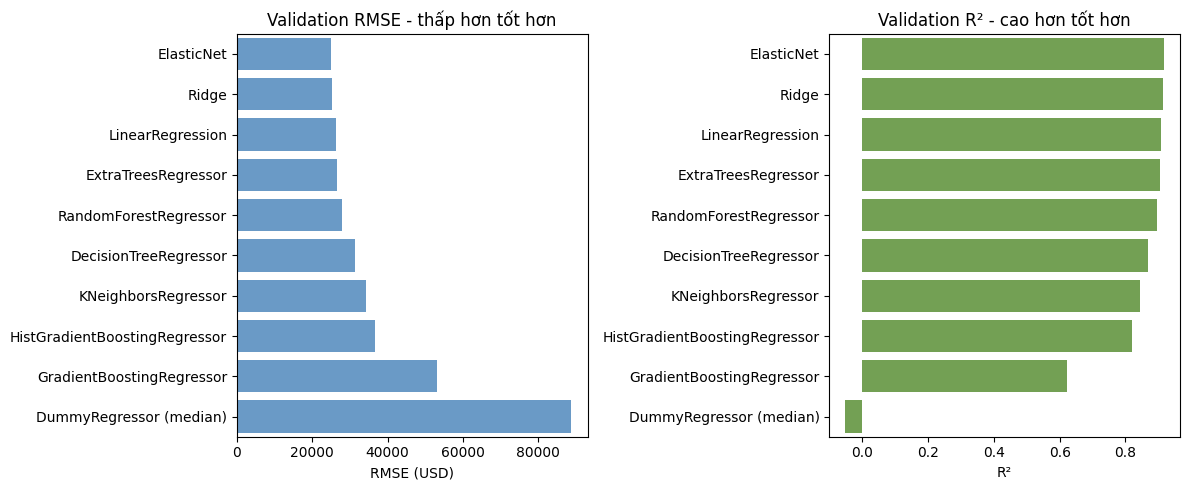

In [6]:
from house_price.modeling import model_definitions

definitions = model_definitions()
benchmark = pd.read_csv(ROOT / "outputs" / "tables" / "validation_model_comparison.csv")
benchmark_view = benchmark[[
    "Model", "Train_RMSE", "RMSE", "MAE", "R2", "RMSLE", "RMSE_gap", "Relative_to_dummy_RMSE_improvement_pct"
]].copy()
benchmark_view["Gap_ratio"] = benchmark_view["RMSE_gap"] / benchmark_view["RMSE"].replace(0, np.nan)

print("Real candidate models:", len(definitions), list(definitions.keys()))
display(benchmark_view.round({
    "Train_RMSE": 0, "RMSE": 0, "MAE": 0, "R2": 4, "RMSLE": 4,
    "RMSE_gap": 0, "Relative_to_dummy_RMSE_improvement_pct": 2, "Gap_ratio": 3,
}))
display(Image(filename=str(ROOT / "outputs" / "figures" / "07_validation_model_comparison.png")))


In [7]:
from house_price.modeling import tuning_space

tuning_table = pd.read_csv(ROOT / "outputs" / "tables" / "tuning_results.csv")
cv_stability = pd.read_csv(ROOT / "outputs" / "tables" / "selected_model_cv_stability.csv")

space_summary = []
for name in ["ElasticNet", "Ridge"]:
    space = tuning_space(name)
    combinations = int(np.prod([len(v) for v in space.values()]))
    space_summary.append({
        "Model": name,
        "Search_parameters": ", ".join(space.keys()),
        "Full_space_combinations": combinations,
        "Canonical_candidates_evaluated": int(tuning_table.loc[tuning_table["Model"] == f"{name} (Tuned)", "Candidates_evaluated"].iloc[0]),
    })

print("Tuning design: predefined regularized linear candidates; 3-fold CV; fixed random_state.")
display(pd.DataFrame(space_summary))
display(tuning_table.round({"RMSE": 2, "MAE": 2, "R2": 4, "RMSLE": 4, "CV_RMSE_mean": 2, "CV_RMSE_std": 2, "CV_train_RMSE_mean": 2, "Search_seconds": 3}))
print("Selected-model CV stability on train:")
display(cv_stability.round(3))


Tuning design: predefined regularized linear candidates; 3-fold CV; fixed random_state.


,Model,Search_parameters,Full_space_combinations,Canonical_candidates_evaluated
0,ElasticNet,"regressor__model__alpha, regressor__model__l1_...",6,3
1,Ridge,regressor__model__alpha,12,3


,Model,RMSE,MAE,R2,RMSLE,CV_RMSE_mean,CV_RMSE_std,CV_train_RMSE_mean,Search_seconds,Candidates_evaluated,Best_params
0,ElasticNet (Tuned),24855.66,15376.31,0.9172,0.1202,39728.85,15890.45,19047.56,2.126,3,"{""regressor__model__l1_ratio"": 0.2, ""regressor..."
1,Ridge (Tuned),25362.19,15209.59,0.9138,0.1191,41703.92,19210.70,24903.71,1.616,3,"{""regressor__model__alpha"": 28.48035868435799}"


Selected-model CV stability on train:


,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_MAE_std,CV_R2_mean,CV_R2_std,CV_train_RMSE_mean
0,39728.847,15890.449,16070.744,1377.375,0.724,0.182,19047.562


## Phase B — MODEL LOCK

### 7. Vì sao ElasticNet được chọn?

Selection phải dựa trên tiêu chí **được code thực thi**, không dựa trên narrative hậu nghiệm.

Protocol hiện tại:

1. primary metric là validation RMSE;
2. project chủ ý tuning hai regularized linear candidates: ElasticNet và Ridge;
3. tolerance là 2%;
4. Ridge chỉ được ưu tiên nếu validation RMSE nằm trong tolerance so với candidate tốt nhất **và** CV RMSE mean không tệ hơn;
5. test không có mặt trong function signature của model selection.

Trong evidence hiện tại, ElasticNet tuned có validation RMSE khoảng **24,855.66 USD**, Ridge tuned khoảng **25,362.19 USD**. Ngưỡng 2% quanh ElasticNet xấp xỉ **25,352.78 USD**, vì vậy Ridge đã nằm hơi ngoài tolerance; đồng thời CV RMSE mean của ElasticNet cũng thấp hơn. Kết quả là ElasticNet thắng mà không cần nhìn test.

Implementation có sort theo tên model khi RMSE và CV hoàn toàn bằng nhau để kết quả deterministic; đây chỉ là **fallback kỹ thuật**, không phải tiêu chí ML độc lập như interpretability hay deployment simplicity.


In [8]:
from dataclasses import asdict
from house_price.selection import ModelSelectionPolicy

policy_defaults = asdict(ModelSelectionPolicy())
assert policy["uses_test"] is False
assert policy["primary_metric"] == policy_defaults["primary_metric"]
assert np.isclose(policy["validation_tolerance"], policy_defaults["validation_tolerance"])
assert policy["locked_model"] == summary["selected_model"]
assert policy["locked_params"] == summary["selected_params"]

best = tuning_table.sort_values(["RMSE", "CV_RMSE_mean", "Model"], kind="mergesort").iloc[0]
ridge = tuning_table.loc[tuning_table["Model"] == "Ridge (Tuned)"].iloc[0]
tolerance_threshold = float(best["RMSE"]) * (1 + float(policy["validation_tolerance"]))
selection_check = pd.DataFrame([{
    "Best_candidate": best["Model"],
    "Best_validation_RMSE": float(best["RMSE"]),
    "Ridge_validation_RMSE": float(ridge["RMSE"]),
    "2pct_threshold": tolerance_threshold,
    "Ridge_within_tolerance": bool(float(ridge["RMSE"]) <= tolerance_threshold),
    "Best_CV_RMSE": float(best["CV_RMSE_mean"]),
    "Ridge_CV_RMSE": float(ridge["CV_RMSE_mean"]),
    "Locked_model": policy["locked_model"],
}])

display(selection_check.round(3))
print("selected_params:", summary["selected_params"])
print("selection_locked_at_utc:", policy["selection_locked_at_utc"])
print("MODEL LOCKED")


,Best_candidate,Best_validation_RMSE,Ridge_validation_RMSE,2pct_threshold,Ridge_within_tolerance,Best_CV_RMSE,Ridge_CV_RMSE,Locked_model
0,ElasticNet (Tuned),24855.662,25362.189,25352.775,False,39728.847,41703.917,ElasticNet


selected_params: {'regressor__model__l1_ratio': 0.2, 'regressor__model__alpha': 0.001}
selection_locked_at_utc: 2026-08-26T11:51:17.424348+00:00
MODEL LOCKED


## Phase C — FINAL HOLDOUT TEST

### 8. Mở test sau khi quyết định đã khóa

Từ thời điểm này notebook mới load `house_test_10.csv` và tách `X_test/y_test`. Test không được dùng để đổi model, đổi alpha/l1-ratio hay chọn lại feature.

Final evaluation trả lời câu hỏi khác validation: **sau toàn bộ quá trình phát triển đã kết thúc, model khóa có tổng quát hóa trên dữ liệu holdout chưa được dùng để selection hay không?**

Ngoài point estimates RMSE/MAE/R²/RMSLE, project dùng bootstrap 300 lần để cung cấp khoảng tin cậy thực nghiệm cho RMSE và MAE. Khoảng này giúp tránh cảm giác chính xác giả khi chỉ báo một con số trên 146 mẫu test.


In [9]:
test = load_house_data("house_test_10.csv")
from house_price.validation import validate_splits

integrity = validate_splits(train, validation, test)
X_test, y_test = split_xy(test)

assert X_test.shape == (146, 79)
assert TARGET not in X_test.columns and ID_COLUMN not in X_test.columns
assert list(X_test.columns) == list(X_train.columns)

print("TEST UNLOCKED AFTER MODEL LOCK:", X_test.shape)
print(integrity)


TEST UNLOCKED AFTER MODEL LOCK: (146, 79)
{'shapes': {'train': (1168, 81), 'validation': (146, 81), 'test': (146, 81)}, 'unique_ids': 1460, 'target': 'SalePrice', 'same_schema': True, 'duplicate_rows': {'train': 0, 'validation': 0, 'test': 0}}


In [10]:
validation_metrics = pd.DataFrame([summary["validation_metrics"]], index=["Validation"])
test_metrics = pd.DataFrame([summary["test_metrics"]], index=["Test"])
metric_comparison = pd.concat([validation_metrics, test_metrics])
metric_comparison["RMSE_change_vs_validation_pct"] = (
    metric_comparison["RMSE"] / float(validation_metrics.loc["Validation", "RMSE"]) - 1
) * 100

ci = summary["test_bootstrap_ci"]
ci_table = pd.DataFrame([
    {"Metric": "RMSE", "Point_estimate": summary["test_metrics"]["RMSE"], "CI95_low": ci["RMSE_95CI"]["lower"], "CI95_high": ci["RMSE_95CI"]["upper"]},
    {"Metric": "MAE", "Point_estimate": summary["test_metrics"]["MAE"], "CI95_low": ci["MAE_95CI"]["lower"], "CI95_high": ci["MAE_95CI"]["upper"]},
])

print("Validation vs final holdout test:")
display(metric_comparison.round(4))
print(f"Bootstrap repetitions: {ci['n_bootstrap']}")
display(ci_table.round(2))


Validation vs final holdout test:


,RMSE,MAE,R2,RMSLE,RMSE_change_vs_validation_pct
Validation,24855.6620,15376.3061,0.9172,0.1202,0.0000
Test,22228.6031,15452.3394,0.9076,0.1177,-10.5693


Bootstrap repetitions: 300


,Metric,Point_estimate,CI95_low,CI95_high
0,RMSE,22228.60,18167.24,26757.93
1,MAE,15452.34,12925.41,18188.23


Residual summary:


,Residual_mean,Residual_median,MAE_from_predictions,Median_AE,MAPE_mean_pct
0,350.65,539.75,15452.34,10598.03,8.87


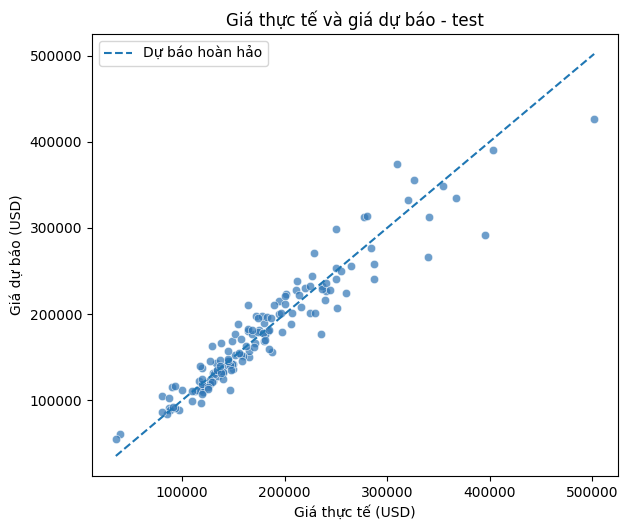

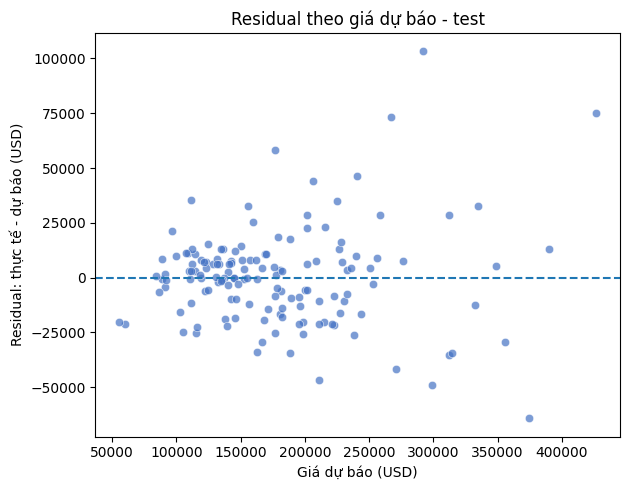

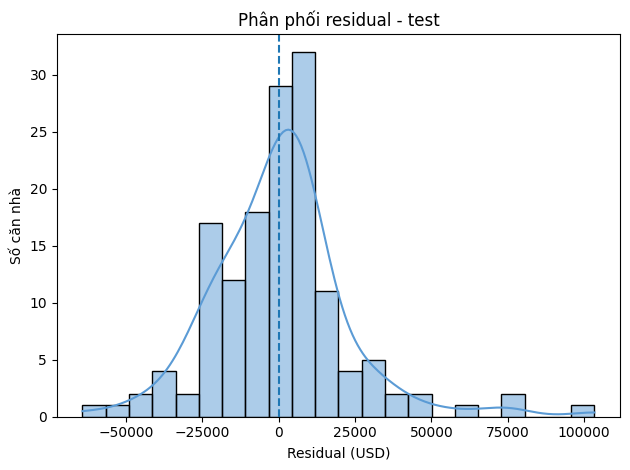

In [11]:
predictions = pd.read_csv(ROOT / "outputs" / "tables" / "test_predictions.csv")
assert len(predictions) == len(test) == 146

residual_summary = pd.DataFrame([{
    "Residual_mean": predictions["Residual"].mean(),
    "Residual_median": predictions["Residual"].median(),
    "MAE_from_predictions": predictions["AbsoluteError"].mean(),
    "Median_AE": predictions["AbsoluteError"].median(),
    "MAPE_mean_pct": predictions["AbsolutePercentageError"].mean(),
}])
print("Residual summary:")
display(residual_summary.round(2))

for filename in ["08_actual_vs_predicted.png", "09_residual_vs_predicted.png", "10_residual_distribution.png"]:
    display(Image(filename=str(ROOT / "outputs" / "figures" / filename)))


Error by actual-price quartile:


,PriceQuartile,Count,MAE,Median_AE,MAPE
0,Q1 - thấp,38,10360.39,7556.78,11.52
1,Q2,35,9551.12,6455.40,6.49
2,Q3,36,14265.90,11862.03,7.77
3,Q4 - cao,37,27418.52,22806.62,9.46


Largest absolute errors:


,Id,ActualSalePrice,PredictedSalePrice,AbsoluteError,Neighborhood,OverallQual,GrLivArea
0,775,395000,291666.04,103333.96,NridgHt,8,1973
1,179,501837,426699.77,75137.23,StoneBr,9,2234
2,378,340000,266687.31,73312.69,Somerst,8,2466
3,1443,310000,374252.33,64252.33,Somerst,10,2007
4,1169,235000,176767.82,58232.18,Edwards,6,2108
5,5,250000,299110.23,49110.23,NoRidge,8,2198
6,1212,164000,210670.87,46670.87,Gilbert,8,1752
7,1038,287000,240498.37,46501.63,CollgCr,8,2263
8,865,250580,206489.41,44090.59,Somerst,7,1372
9,336,228950,270718.81,41768.81,Timber,5,1786


Neighborhood segments with enough observations, sorted by MAE:


,Neighborhood,Count,MAE,MAPE,OverallQual
0,Somerst,9,30516.16,11.38,NaN
1,NoRidge,4,30231.44,10.91,NaN
2,NridgHt,8,28646.95,9.40,NaN
3,Timber,6,20933.67,11.03,NaN
4,ClearCr,5,20003.42,8.74,NaN
5,IDOTRR,4,18593.16,24.03,NaN
6,Crawfor,5,18471.23,13.06,NaN
7,Mitchel,5,18414.82,12.20,NaN


Overall-quality segments, sorted by MAE:


,Neighborhood,Count,MAE,MAPE,OverallQual
8,NaN,3,45768.80,10.97,9.0
9,NaN,2,38588.37,11.97,10.0
7,NaN,16,32198.16,12.39,8.0
0,NaN,1,21017.41,53.48,1.0
1,NaN,1,20196.38,57.20,2.0
6,NaN,29,16268.04,7.87,7.0
5,NaN,42,11193.85,6.43,6.0
3,NaN,10,11116.98,10.38,4.0


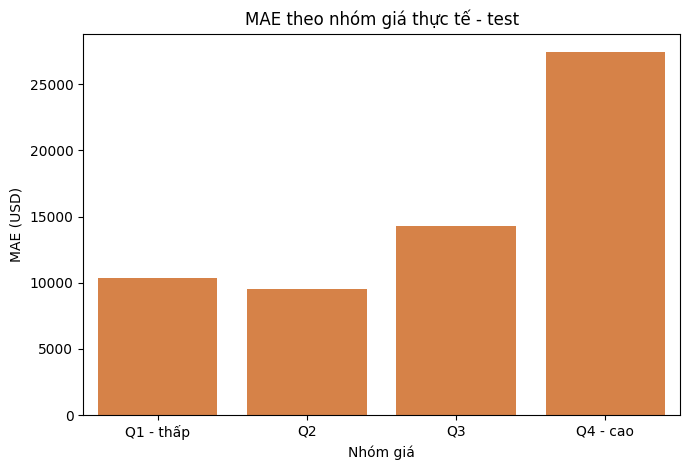

In [12]:
quartile_errors = pd.read_csv(ROOT / "outputs" / "tables" / "error_by_price_quartile.csv")
top_errors = pd.read_csv(ROOT / "outputs" / "tables" / "top10_absolute_errors.csv")
by_neighborhood = pd.read_csv(ROOT / "outputs" / "tables" / "error_by_neighborhood.csv")
by_quality = pd.read_csv(ROOT / "outputs" / "tables" / "error_by_overall_quality.csv")

print("Error by actual-price quartile:")
display(quartile_errors.round(2))
print("Largest absolute errors:")
display(top_errors[["Id", "ActualSalePrice", "PredictedSalePrice", "AbsoluteError", "Neighborhood", "OverallQual", "GrLivArea"]].round(2))
print("Neighborhood segments with enough observations, sorted by MAE:")
display(by_neighborhood.sort_values("MAE", ascending=False).head(8).round(2))
print("Overall-quality segments, sorted by MAE:")
display(by_quality.sort_values("MAE", ascending=False).head(8).round(2))
display(Image(filename=str(ROOT / "outputs" / "figures" / "11_error_by_price_quartile.png")))


### 9. Error analysis và explainability

Test RMSE thấp hơn validation RMSE trong split hiện tại, nhưng không nên diễn giải điều đó là model “tốt hơn trên test”; hai tập có cỡ mẫu nhỏ và thành phần quan sát khác nhau. Điều cần theo dõi là pattern sai số:

- nhóm Q4 giá cao có MAE lớn nhất, cho thấy các căn nhà cao cấp/hiếm vẫn khó mô tả;
- một vài sai số tuyệt đối lớn có thể làm RMSE tăng đáng kể so với MAE;
- segment analysis theo `Neighborhood` và `OverallQual` giúp phát hiện nhóm mà model có thể cần thêm dữ liệu hoặc đặc trưng.

Permutation importance đo mức suy giảm score khi hoán vị một input feature trên model đã khóa. Nó hữu ích để giải thích model ở mức dự báo nhưng **không phải bằng chứng nhân quả**. Importance cũng phụ thuộc sample và tương quan giữa các features; vì vậy cần đọc cùng EDA và domain knowledge.


Top 15 permutation-importance features:


,Feature,Importance_mean,Importance_std,Repeats,Sample_size
0,GrLivArea,9910.12,1840.31,20,50
1,OverallQual,8734.33,2375.29,20,50
2,Neighborhood,5256.71,2250.60,20,50
3,GarageCars,3076.45,1148.80,20,50
4,LotArea,2269.53,1749.56,20,50
5,YearBuilt,1777.64,1522.11,20,50
6,KitchenQual,1730.04,419.12,20,50
7,TotalBsmtSF,1321.19,620.20,20,50
8,YearRemodAdd,762.10,571.38,20,50
9,GarageArea,699.45,338.41,20,50


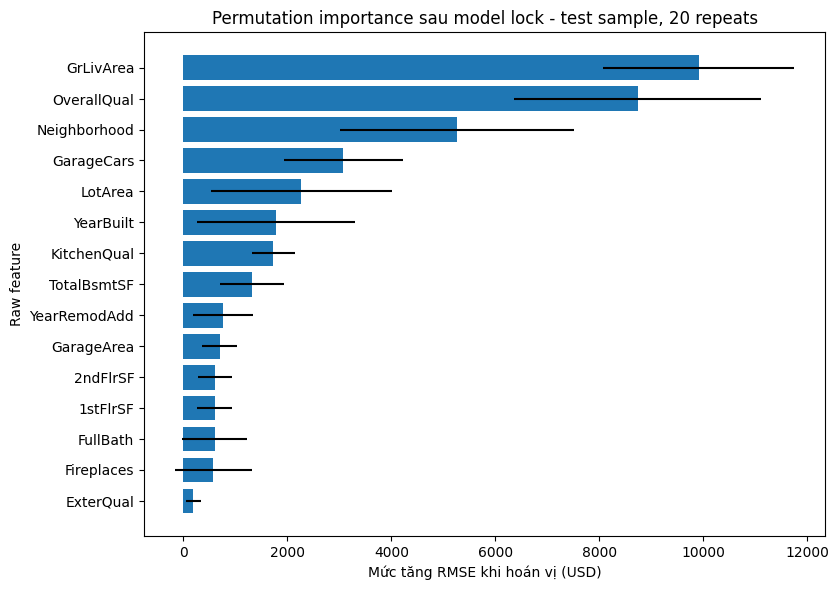

Top-5 consistency: ['GrLivArea', 'OverallQual', 'Neighborhood', 'GarageCars', 'LotArea']


In [13]:
importance = pd.read_csv(ROOT / "outputs" / "tables" / "permutation_importance.csv")
assert (importance.head(15)["Repeats"] == 20).all()
assert (importance["Sample_size"] == 50).all()

print("Top 15 permutation-importance features:")
display(importance.head(15).round(2))
display(Image(filename=str(ROOT / "outputs" / "figures" / "12_permutation_importance.png")))

summary_top = [row["Feature"] for row in summary["top_features"][:5]]
table_top = importance.head(5)["Feature"].tolist()
assert summary_top == table_top
print("Top-5 consistency:", table_top)


Artifact steps: ['feature_engineering', 'preprocessor', 'model']
Artifact SHA-256: 5101114637e8001c91f06a42737cd3cc8ee143cb1d6a3a27631a41b48f3efcf1
Schema raw feature count: 79
Single prediction: 299110.23


,PredictedSalePrice
0,299110.23
1,136080.93
2,122819.32
3,198197.65
4,230134.53


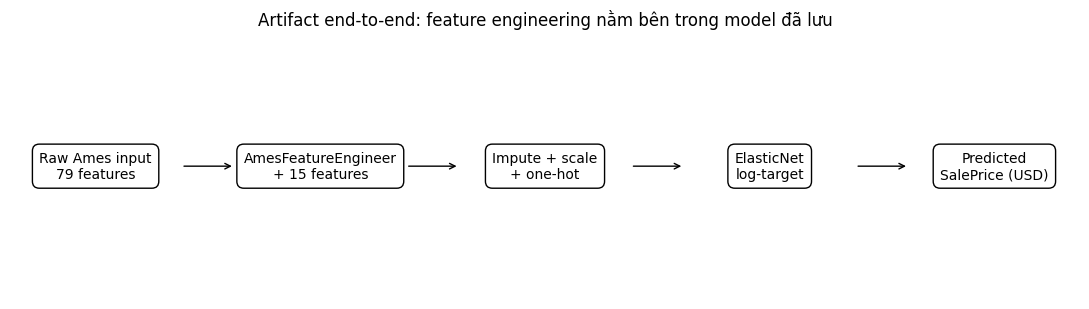

In [14]:
# End-to-end artifact + inference contract. Không fit hoặc ghi đè canonical artifact.
model = joblib.load(model_path)
schema = json.loads((ROOT / "models" / "input_schema.json").read_text(encoding="utf-8"))

assert sha256_file(model_path) == summary["artifact"]["model_sha256"]
assert schema["feature_count"] == summary["input_schema_feature_count"] == 79
assert list(model.regressor.named_steps.keys()) == ["feature_engineering", "preprocessor", "model"]

reload_pred = model.predict(X_test.head(3))
assert np.allclose(reload_pred, summary["artifact"]["reload_predictions"], rtol=0, atol=1e-6)

from backend.service import predict_one, predict_batch
single = predict_one(X_test.iloc[0].to_dict())
batch = predict_batch(X_test.head(5).copy())
assert np.isclose(single, reload_pred[0], rtol=0, atol=1e-6)
assert len(batch) == 5 and "PredictedSalePrice" in batch.columns

print("Artifact steps:", list(model.regressor.named_steps.keys()))
print("Artifact SHA-256:", summary["artifact"]["model_sha256"])
print("Schema raw feature count:", schema["feature_count"])
print("Single prediction:", round(single, 2))
display(batch[["PredictedSalePrice"]].round(2))
display(Image(filename=str(ROOT / "outputs" / "figures" / "13_deployment_architecture.png")))


### 10. Từ notebook đến sản phẩm: architecture, testing và reproducibility

Artifact triển khai có contract:

```text
Raw Ames input (79 features)
→ AmesFeatureEngineer (+15)
→ median/scale + Missing/one-hot
→ ElasticNet trên log-target
→ inverse log transform
→ Predicted SalePrice (USD)
```

Các lớp chính của project:

- `src/house_price/`: scientific/business logic dùng lại được;
- `models/`: canonical joblib + schema/metadata;
- `backend/`: single/batch inference, không retrain;
- `app/`: giao diện Streamlit;
- `tests/`: unit/integration/architecture tests;
- `outputs/`: canonical research evidence;
- `reports/`, `slides/`: tài liệu trình bày.

Notebook **không chạy pytest/coverage trong từng Run All**, vì đó là QA workflow riêng. Thay vào đó nó đọc machine-readable final evidence sau freshness check. Bản audit hiện tại ghi 67 tests PASS và source coverage 99.9% trên đúng scope `src/house_price + backend`.

Các lệnh kiểm tra độc lập khi chuẩn bị nộp:

```bash
pytest -q
coverage erase
coverage run --source=src/house_price,backend -m pytest
coverage report -m
python scripts/check_project_consistency.py
python scripts/execute_notebooks.py
```

Streamlit code tồn tại trong project nhưng notebook không tự tuyên bố một deployment URL nếu chưa được verified ở môi trường nộp.


In [15]:
test_summary = json.loads((ROOT / "outputs" / "audit" / "test_summary.json").read_text(encoding="utf-8"))
coverage = json.loads((ROOT / "outputs" / "audit" / "coverage.json").read_text(encoding="utf-8"))

assert test_summary["tests_failed"] == 0
assert test_summary["tests_passed"] == 69
assert coverage["scope"] == ["src/house_price", "backend"]
assert coverage["total_coverage"] >= 95

qa_overview = pd.DataFrame([{
    "Tests_passed": test_summary["tests_passed"],
    "Tests_failed": test_summary["tests_failed"],
    "Warnings_canonical_run": test_summary["warnings"],
    "Source_coverage_pct": coverage["display_coverage"],
    "Coverage_scope": " + ".join(coverage["scope"]),
}])

environment = pd.DataFrame([
    {"Source": "Current notebook", "Python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__, "random_state": RANDOM_STATE},
    {"Source": "Canonical training", "Python": summary["environment"]["python"], "pandas": summary["environment"]["pandas"], "numpy": summary["environment"]["numpy"], "sklearn": summary["environment"]["scikit_learn"], "random_state": summary["environment"]["random_state"]},
])

component_map = pd.DataFrame([
    ("ML core", "src/house_price/"),
    ("Canonical artifact", "models/house_price_pipeline.joblib"),
    ("Inference", "backend/ + app/"),
    ("Tests", "tests/"),
    ("Canonical evidence", "outputs/"),
    ("Human deliverables", "reports/ + slides/"),
], columns=["Layer", "Location"])

display(qa_overview)
display(environment)
display(component_map)
print("Canonical evidence timestamps:", test_summary["generated_at_utc"], coverage["generated_at_utc"])


,Tests_passed,Tests_failed,Warnings_canonical_run,Source_coverage_pct,Coverage_scope
0,69,0,0,99.7,src/house_price + backend


,Source,Python,pandas,numpy,sklearn,random_state
0,Current notebook,3.13.5,2.2.3,2.3.5,1.8.0,42
1,Canonical training,3.13.5,2.2.3,2.3.5,1.8.0,42


,Layer,Location
0,ML core,src/house_price/
1,Canonical artifact,models/house_price_pipeline.joblib
2,Inference,backend/ + app/
3,Tests,tests/
4,Canonical evidence,outputs/
5,Human deliverables,reports/ + slides/


Canonical evidence timestamps: 2026-10-05T00:14:31.029791+00:00 2026-10-05T00:14:31.052448+00:00


## 11. Kết luận, giới hạn và câu hỏi tự kiểm tra

### Kết luận chính

- Development và selection trong notebook chỉ dùng train + validation; holdout target chỉ được mở sau model lock.
- Final model canonical là **ElasticNet** với `alpha = 0.001`, `l1_ratio = 0.2`.
- Validation đạt RMSE khoảng **24,855.66 USD**, MAE **15,376.31 USD**, R² **0.9172**, RMSLE **0.1202**.
- Final holdout test đạt RMSE **22,228.60 USD**, MAE **15,452.34 USD**, R² **0.9076**, RMSLE **0.1177**.
- Bootstrap 95% CI cho thấy metric trên 146 test samples vẫn có bất định đáng kể; không nên chỉ nhìn point estimate.
- `GrLivArea`, `OverallQual`, `Neighborhood`, `GarageCars`, `LotArea` nằm trong nhóm permutation importance nổi bật của model hiện tại.
- Error analysis cho thấy nhóm nhà giá cao vẫn khó dự báo hơn theo sai số USD tuyệt đối.
- Canonical artifact nhận trực tiếp 79 raw features và chứa feature engineering + preprocessing + model trong cùng pipeline.

### Giới hạn

Kết quả chỉ chứng minh hiệu năng trên split Ames hiện có. Dữ liệu có 1.460 quan sát, thuộc bối cảnh địa lý/thời kỳ cụ thể và không đại diện trực tiếp cho thị trường nhà ở Việt Nam hiện tại. Split đã được cung cấp sẵn nên project có thể kiểm tra integrity/hash nhưng không thể chứng minh lại thuật toán tạo split ban đầu. Permutation importance không phải causal inference. Nếu triển khai thật cần thêm dữ liệu mới, monitoring drift, validation theo thời gian/khu vực và calibration/uncertainty phù hợp nghiệp vụ.

### Câu hỏi tự kiểm tra khi bảo vệ

1. Vì sao `NA` ở `PoolQC` hoặc `Alley` không nên tự động coi là dữ liệu hỏng?
2. Vì sao log-target hợp lý với phân phối `SalePrice` của train?
3. Tại sao Accuracy/Precision/Recall/F1 không dùng làm metric chính cho bài toán này?
4. ExtraTrees có train RMSE rất thấp nhưng validation gap lớn nói lên điều gì?
5. Vì sao project chỉ tuning ElasticNet và Ridge dù benchmark có nhiều model hơn?
6. Điều kiện nào khiến Ridge có thể thắng ElasticNet theo selection policy hiện tại?
7. Nếu dùng test để chọn `alpha` rồi báo chính metric test đó, đánh giá còn khách quan không?
8. Vì sao RMSE và MAE có thể kể hai câu chuyện khác nhau ở nhóm nhà giá cao?
9. Permutation importance khác causal importance như thế nào?
10. Vì sao đưa feature engineering vào artifact tốt hơn việc để Streamlit tự tính feature?
11. Nếu source thay đổi nhưng `summary.json` không đổi, freshness gate phải phản ứng ra sao?
12. Trước khi đưa model sang một thành phố/thời kỳ khác, cần kiểm tra những dạng drift nào?

**Thông điệp bảo vệ:** notebook không chỉ báo một con số đẹp; nó chứng minh đường đi từ dữ liệu → protocol → selection → holdout evaluation → error analysis → artifact → QA bằng các nguồn evidence nhất quán.
